# Can we predict an early spring?

## Problem
A new seed has entered the market. It is a variant of corn that is capable of being harvested twice if Farmers plant early enough. These crops for the first harvest will only survive if an early spring comes, and the way it is predicted now is unreliable and prone to failure. As of right now, Punxsutawney Phil predicts wether or not an early spring is upon us. Our client, Farmer Jeff, wants a better predictor so they can have the best chance to turn this double harvest plan into a profit. The cost of being wrong is wasting seeds. The price of seeds makes it so that 5 wrong predictions in a row will hurt profits, so we must catch early springs without long strings of false alarms.

## Our Project
We built a model that predicts every March 1st if an early spring is coming or not. Using 57 years of data for training that encompasses farm weather and soil data. We cleaned and engineered the features and compared 10 different models using cross validation. 5 of the models were tuned, and we decided on random forest as our model. We want to see how well our model scores on the 15 test years we have that were not used for training or tuning. 

In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
set_config(transform_output="pandas")

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [3]:
# Copied from the Preparation notebook (needed to load preprocessor.pkl)
class EarlySpringFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, add_deltas=True, add_pre_march_trend=True, combine_oni=True, drop_redundant=True, use_year=False,
                 delta_features=("soil_temp_mean", "farm_avg_temp_mean", "om_temp_mean"),
                 redundant_features=("soil_thawed_days_jan", "soil_thawed_days_feb", "farm_freezing_days_feb")):
        self.add_deltas = add_deltas
        self.add_pre_march_trend = add_pre_march_trend
        self.combine_oni = combine_oni
        self.drop_redundant = drop_redundant
        self.use_year = use_year
        self.delta_features = delta_features
        self.redundant_features = redundant_features

    def fit(self, X, y=None):
        self.feature_names_out_ = self._engineer(X).columns.to_numpy()
        return self

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_

    def transform(self, X):
        return self._engineer(X)

    def _engineer(self, X):
        data = X.drop(columns="early_spring", errors="ignore")
        data["phil_pred"] = data["phil_pred"].astype(int)

        if self.add_deltas:
            for name in self.delta_features:
                data[f"{name}_delta"] = data[f"{name}_feb"] - data[f"{name}_jan"]

        if self.add_pre_march_trend:
            for prefix in ["farm_avg_temp", "soil_mean_soil_temp", "om_temperature_2m_mean"]:
                d1 = f"{prefix}_d_minus_1"
                d7 = f"{prefix}_d_minus_7"
                if d1 in data.columns and d7 in data.columns:
                    data[f"{prefix}_7d_trend"] = data[d1] - data[d7]

        if self.combine_oni:
            data["oni_winter_avg"] = data[["oni_prev_nov", "oni_prev_dec"]].mean(axis=1)
            data = data.drop(columns=["oni_prev_nov", "oni_prev_dec"])

        if self.drop_redundant:
            data = data.drop(columns=list(self.redundant_features), errors="ignore")

        if self.use_year:
            data["year"] = data.index.to_numpy()

        return data

In [4]:
with open("model.pkl", "rb") as f:
    model = pickle.load(f)

# The test set has not been used for anything yet - this is the final, honest check
test_set = pd.read_parquet("test_set.parquet")
X_test = test_set.drop(columns="early_spring")
y_test = test_set["early_spring"].astype(int)

model_preds = model.predict(X_test)
phil_preds = X_test["phil_pred"].astype(int)

## Scoring

How we judge it. Early springs are only about a quarter of years, so accuracy is misleading: “always late” would score 73% on this test set and help nobody. We focus on recall (what share of early springs we catch), precision (what share of our “early” calls are right, so how often seed is wasted), and F1, which balances the two. We would prefer a higher recall at the cost of precision due to our wiggle room on error.

In [5]:
# Model vs Phil on the test set
scores = pd.DataFrame({
    name: {
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds),
        "f1": f1_score(y_test, preds),
    }
    for name, preds in [("Model", model_preds), ("Phil", phil_preds)]
}).T
scores.round(3)

,accuracy,precision,recall,f1
Model,0.667,0.333,0.25,0.286
Phil,0.600,0.250,0.25,0.250


## Results
Unfortunately, the model and Phil are quite close. The model scores with an accuracy of 67%, precision of 33%, recall of 25% and an f1 score of 29%. Phils scores are 60%, 25%, 25% and 25% respectively. The model is slightly ahead on accuracy precision and f1. However, we disregard accuracy because it is a misleading score where our baseline of just choosing yes is high in accuracy. Each approaches only caught 1 out of the 4 early springs. Our model is only better because of its number of false alarms being fewer.

Our cross validation suggested a much higher performance, however we think the gap is to be expected because there were only 57 training years and 14 early springs and our tuning was only able to do so much with the small amount of data we had. The test set also only had 4 springs, so not catching even 1 spring takes a huge hit on our scores. We can't say the model did better than Phil... but it didn't do worse!

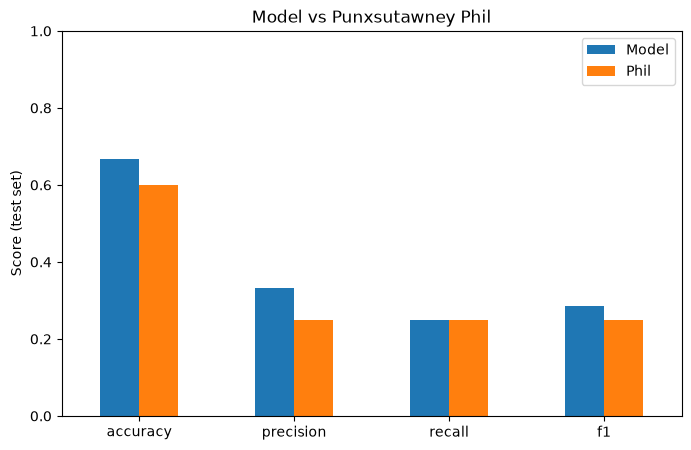

In [6]:
scores.T.plot.bar(figsize=(8, 5), rot=0)
plt.ylim(0, 1)
plt.ylabel("Score (test set)")
plt.title("Model vs Punxsutawney Phil")
plt.show()

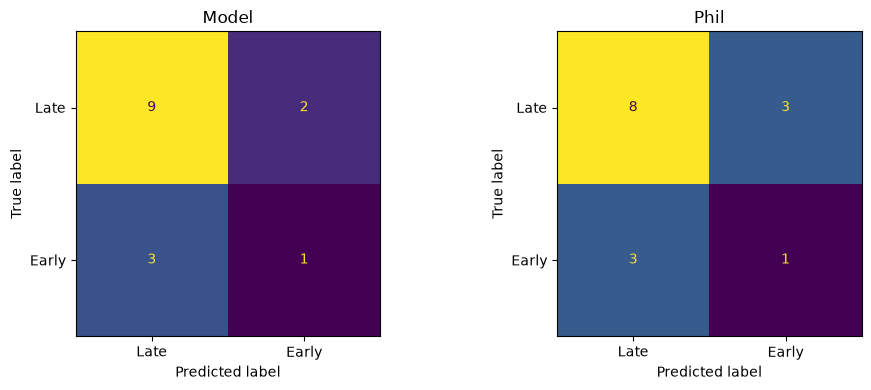

In [7]:
# Rows = actual, columns = predicted (0 = late spring, 1 = early spring)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, preds) in zip(axes, [("Model", model_preds), ("Phil", phil_preds)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds), display_labels=["Late", "Early"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()

For farmers the important cell is the top right: a false alarm, where we say early and spring comes late, which wastes seed. The model made 2 false alarms out of 11 late years (18%) against Phil’s 3 (27%). Both missed 3 of the 4 early springs, and a miss costs the second harvest. The model’s precision (0.33) is only slightly above the 27% you would get by guessing “early” every year, so its “early” calls are barely more reliable than chance.

In [8]:
# Year-by-year predictions on the test set
pd.DataFrame({
    "actual": y_test.map({1: "Early", 0: "Late"}),
    "phil": phil_preds.map({1: "Early", 0: "Late"}),
    "model": pd.Series(model_preds, index=y_test.index).map({1: "Early", 0: "Late"}),
}).sort_index()

,actual,phil,model
year,,,
1951,Early,Late,Early
1958,Late,Late,Late
1961,Late,Late,Late
1967,Late,Late,Late
1971,Late,Late,Late
1973,Late,Late,Late
1975,Late,Early,Late
1983,Late,Early,Late
1997,Late,Early,Early


The model was right where Phil was wrong in three years (1951, 1975, 1983), and Phil was right where the model was wrong in two (2016, 2026). Both were right in seven years, mostly late springs, and both were wrong in three (1997, 1998 and 2012). Neither predictor caught the early springs of 1998 or 2012, so those years likely had conditions our features cannot see. The model’s two false alarms (1997 and 2026) were decades apart, so there was no streak near the five-in-a-row limit. With only 15 test years, streaks cannot really be tested.

## Limitations
* Small data. Only 57 training years and 14 early springs, against about 113 features. The model can only learn weak patterns, and results swing a lot.
* A tiny test set. 15 years with 4 early springs. The difference between the model and Phil is one false alarm, which is well within noise.
* Optimistic tuning. We picked the best of 50 to 100 random configurations per model on the same data, so cross-validation scores overstated performance. The test drop shows this.
* Class imbalance. Early springs are about a quarter of years, which is why accuracy is a poor yardstick here.
* Noisy features. Many features are single-day weather readings that likely carry little real signal.
* Missing information. A human forecaster uses March outlooks, regional snowpack and local experience. The model sees none of these.

## Use Case For Farmers
We think our model can still be useful, it should be used as another source of input next to other things like personal judgement, phil, and current forecasts. Farmers could consider only planting part of the seed supply early or stepping back from a prediction if 3-4 have been false positives in a row so profits arent bled into.

The big takeaway is that more data is needed. Our noisy features (the single day features) could be dropped and replaced with their averages. Another interesting batch of data that could be useful is March forecasts. We could also lower the threshold for decision making to swap precision for recall. 